In [1]:
%pip install pandas openpyxl matplotlib

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   ---------------------------------------- 0/2 [et-xmlfile]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
from pathlib import Path
import re
import unicodedata

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Hiển thị nội dung dài hơn khi xem bảng
pd.set_option("display.max_colwidth", 150)

In [2]:
file_path = Path("data_ggmap.xlsx")

if not file_path.exists():
    raise FileNotFoundError(
        f"Không tìm thấy file: {file_path.resolve()}"
    )

df = pd.read_excel(
    file_path,
    sheet_name=0,
    engine="openpyxl"
)

# Xóa khoảng trắng thừa ở đầu và cuối tên cột
df.columns = df.columns.astype(str).str.strip()

print("Số dòng:", len(df))
print("Tên các cột:", df.columns.tolist())

display(df.head())

Số dòng: 43
Tên các cột: ['Số thứ tự', 'Nội dung', 'Ngày thu thập', 'Ghi chú', 'Nhãn']


,Số thứ tự,Nội dung,Ngày thu thập,Ghi chú,Nhãn
0,1,"Đại học Mỏ – Địa chất là một môi trường học tập đáng để tìm hiểu, đặc biệt dành cho những bạn yêu thích các ngành kỹ thuật, địa chất, khai thác mỏ...",14/11/2026,Không,Tích cực
1,2,"Là một mọi trường tốt để mn học tập và phát triển bản thân, trường sửa sang lại khá đẹp và xây thêm khu mới, nhiều hoạt động phát triển kỹ năng mề...",14/11/2026,Không,Tích cực
2,3,"Tốt rồi, ngành công nghệ thông tin ở trường này là một trong các ngành công nghệ mũi nhọn, kết hợp thế mạnh truyền thống của khoa học trái đất, ko...",14/11/2026,Không,Trung lập
3,4,"Trong một lần có dịp ghé thăm Đại học Mỏ – Địa chất, mình khá ấn tượng với không gian và diện mạo của trường. Dù chỉ tham quan trong thời gian ngắ...",14/11/2026,Không,Trung lập
4,5,"Theo quan điểm cá nhân của tôi, hệ thống giáo dục Việt Nam tốt hơn rất nhiều so với hệ thống giáo dục Anh Quốc. Việt Nam chưa đưa các chính sách D...",14/11/2026,Không,Trung lập


In [3]:
column_mapping = {
    "Số thứ tự": "review_id",
    "Nội dung": "text_original",
    "Ngày thu thập": "collected_at",
    "Ghi chú": "note",
    "Nhãn": "label"
}

required_columns = list(column_mapping.keys())

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"File Excel còn thiếu các cột: {missing_columns}"
    )

df = df.rename(columns=column_mapping)

# Chuyển số thứ tự thành mã: 1 → GM001, 2 → GM002
def create_review_id(value):
    if pd.isna(value):
        return ""

    number = float(value)

    if not number.is_integer() or number <= 0:
        raise ValueError(f"Số thứ tự không hợp lệ: {value}")

    return f"GM{int(number):03d}"

df["review_id"] = df["review_id"].apply(create_review_id)
df["source"] = "google_maps"

display(df.head())

,review_id,text_original,collected_at,note,label,source
0,GM001,"Đại học Mỏ – Địa chất là một môi trường học tập đáng để tìm hiểu, đặc biệt dành cho những bạn yêu thích các ngành kỹ thuật, địa chất, khai thác mỏ...",14/11/2026,Không,Tích cực,google_maps
1,GM002,"Là một mọi trường tốt để mn học tập và phát triển bản thân, trường sửa sang lại khá đẹp và xây thêm khu mới, nhiều hoạt động phát triển kỹ năng mề...",14/11/2026,Không,Tích cực,google_maps
2,GM003,"Tốt rồi, ngành công nghệ thông tin ở trường này là một trong các ngành công nghệ mũi nhọn, kết hợp thế mạnh truyền thống của khoa học trái đất, ko...",14/11/2026,Không,Trung lập,google_maps
3,GM004,"Trong một lần có dịp ghé thăm Đại học Mỏ – Địa chất, mình khá ấn tượng với không gian và diện mạo của trường. Dù chỉ tham quan trong thời gian ngắ...",14/11/2026,Không,Trung lập,google_maps
4,GM005,"Theo quan điểm cá nhân của tôi, hệ thống giáo dục Việt Nam tốt hơn rất nhiều so với hệ thống giáo dục Anh Quốc. Việt Nam chưa đưa các chính sách D...",14/11/2026,Không,Trung lập,google_maps


In [4]:
def normalize_text(text):
    # Nếu ô bị trống, trả về chuỗi rỗng
    if pd.isna(text):
        return ""

    text = str(text)

    # Chuẩn hóa cách biểu diễn ký tự tiếng Việt
    text = unicodedata.normalize("NFC", text)

    # Chuyển thành chữ thường
    text = text.lower()

    # Gộp nhiều khoảng trắng, tab, xuống dòng
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [5]:
example = "  Giảng viên   KHÔNG giảng nhanh.\nRất dễ hiểu!  "

print(normalize_text(example))

giảng viên không giảng nhanh. rất dễ hiểu!


In [6]:
df["text_clean"] = df["text_original"].apply(normalize_text)

display(df[["text_original", "text_clean"]].head())

,text_original,text_clean
0,"Đại học Mỏ – Địa chất là một môi trường học tập đáng để tìm hiểu, đặc biệt dành cho những bạn yêu thích các ngành kỹ thuật, địa chất, khai thác mỏ...","đại học mỏ – địa chất là một môi trường học tập đáng để tìm hiểu, đặc biệt dành cho những bạn yêu thích các ngành kỹ thuật, địa chất, khai thác mỏ..."
1,"Là một mọi trường tốt để mn học tập và phát triển bản thân, trường sửa sang lại khá đẹp và xây thêm khu mới, nhiều hoạt động phát triển kỹ năng mề...","là một mọi trường tốt để mn học tập và phát triển bản thân, trường sửa sang lại khá đẹp và xây thêm khu mới, nhiều hoạt động phát triển kỹ năng mề..."
2,"Tốt rồi, ngành công nghệ thông tin ở trường này là một trong các ngành công nghệ mũi nhọn, kết hợp thế mạnh truyền thống của khoa học trái đất, ko...","tốt rồi, ngành công nghệ thông tin ở trường này là một trong các ngành công nghệ mũi nhọn, kết hợp thế mạnh truyền thống của khoa học trái đất, ko..."
3,"Trong một lần có dịp ghé thăm Đại học Mỏ – Địa chất, mình khá ấn tượng với không gian và diện mạo của trường. Dù chỉ tham quan trong thời gian ngắ...","trong một lần có dịp ghé thăm đại học mỏ – địa chất, mình khá ấn tượng với không gian và diện mạo của trường. dù chỉ tham quan trong thời gian ngắ..."
4,"Theo quan điểm cá nhân của tôi, hệ thống giáo dục Việt Nam tốt hơn rất nhiều so với hệ thống giáo dục Anh Quốc. Việt Nam chưa đưa các chính sách D...","theo quan điểm cá nhân của tôi, hệ thống giáo dục việt nam tốt hơn rất nhiều so với hệ thống giáo dục anh quốc. việt nam chưa đưa các chính sách d..."


In [7]:
# Chuẩn hóa mã nhưng không thay đổi mã đã đặt
df["review_id"] = (
    df["review_id"]
    .fillna("")
    .astype(str)
    .str.strip()
)

# Nội dung trống
empty_text = df["text_clean"].eq("")

# Mã bị thiếu
missing_id = df["review_id"].eq("")

# Mã xuất hiện nhiều lần
duplicate_id = (
    df["review_id"].duplicated(keep=False)
    & ~missing_id
)

# Nội dung giống nhau sau chuẩn hóa
duplicate_text = (
    df["text_clean"].duplicated(keep=False)
    & ~empty_text
)

print("Số dòng nội dung trống:", int(empty_text.sum()))
print("Số dòng thiếu mã:", int(missing_id.sum()))
print("Số dòng có mã trùng:", int(duplicate_id.sum()))
print("Số dòng thuộc nhóm nội dung trùng:", int(duplicate_text.sum()))

display(
    df.loc[
        empty_text | missing_id | duplicate_id | duplicate_text,
        ["review_id", "text_original", "label"]
    ]
)

Số dòng nội dung trống: 6
Số dòng thiếu mã: 0
Số dòng có mã trùng: 0
Số dòng thuộc nhóm nội dung trùng: 0


,review_id,text_original,label
37,GM038,NaN,NaN
38,GM039,NaN,NaN
39,GM040,NaN,NaN
40,GM041,NaN,NaN
41,GM042,NaN,NaN
42,GM043,NaN,NaN


In [8]:
df["label_clean"] = df["label"].apply(normalize_text)

valid_labels = ["tiêu cực", "trung lập", "tích cực"]

# Đã nhập nhãn nhưng sai quy ước
invalid_label = (
    df["label_clean"].ne("")
    & ~df["label_clean"].isin(valid_labels)
)

# Có nội dung nhưng chưa gán nhãn
missing_label = (
    df["text_clean"].ne("")
    & df["label_clean"].eq("")
)

print("Số dòng có nhãn không hợp lệ:", int(invalid_label.sum()))
print("Số dòng chưa gán nhãn:", int(missing_label.sum()))

display(
    df.loc[
        invalid_label | missing_label,
        ["review_id", "text_original", "label", "note"]
    ]
)

Số dòng có nhãn không hợp lệ: 0
Số dòng chưa gán nhãn: 13


,review_id,text_original,label,note
24,GM025,Thầy cô siêu siêu nhiệt huyết,NaN,Không
25,GM026,Trường sạch sẽ rộng rãi và có chuyên môn giảng dạy cao,NaN,Không
26,GM027,5 sao cho sự tận tình chỉ dạy của các thầy cô ạ,NaN,Không
27,GM028,Môi trường học tập tốt!!! Thầy cô giảng viên thân thiện !!!,NaN,Không
28,GM029,Chất lượng đào tạo của nhà trường rất tốt,NaN,Không
29,GM030,tệ,NaN,Không
30,GM031,Kém,NaN,Không
31,GM032,"trường đẹp, đào tạo tốt",NaN,Không
32,GM033,Trường dạy quá tốt ^^,NaN,Không
33,GM034,Kém mọi mặt,NaN,Không


Số dòng có nội dung và nhãn hợp lệ: 24


,Số lượng
label_clean,
tiêu cực,1
trung lập,5
tích cực,18


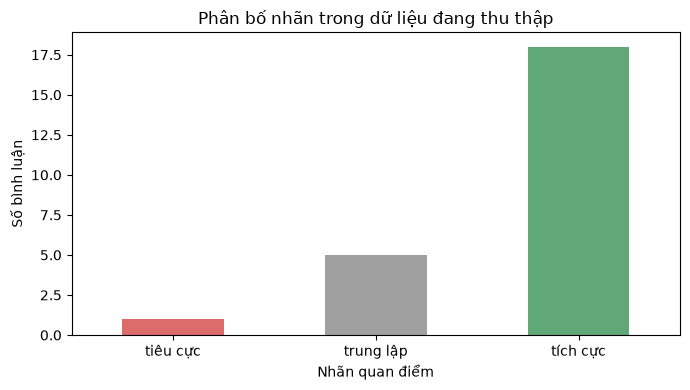

In [9]:
selected = df.loc[
    df["text_clean"].ne("")
    & df["label_clean"].isin(valid_labels)
].copy()

counts = (
    selected["label_clean"]
    .value_counts()
    .reindex(valid_labels, fill_value=0)
)

print("Số dòng có nội dung và nhãn hợp lệ:", len(selected))
display(counts.rename("Số lượng").to_frame())

if not selected.empty:
    counts.plot(
        kind="bar",
        color=["#dc6b6b", "#a0a0a0", "#61a879"],
        figsize=(7, 4)
    )

    plt.title("Phân bố nhãn trong dữ liệu đang thu thập")
    plt.xlabel("Nhãn quan điểm")
    plt.ylabel("Số bình luận")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()
else:
    print("Chưa có dữ liệu phù hợp để vẽ biểu đồ.")